In [1]:
# 10. Confirm independently written predictions before experiments; initialize environment.
from pathlib import Path
import os, sys, json, time, platform, importlib.metadata
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.preprocessing import StandardScaler
from gensim.models import Word2Vec
from preprocessing import (load_imdb, inspect_dataset, clean_official_splits,
                           normalize_text, tokenize, average_embeddings,
                           DATASET_URL, DATASET_REVISION, FILES, sha256_file)
BASE = Path.cwd()
assert (BASE / "preprocessing.py").exists(), "Run the notebook with lab04 as working directory"
DATA = BASE / "data"
TABLES = BASE / "outputs"
TABLES.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
LABELS = [0, 1]
LABEL_NAMES = ["negative", "positive"]
# The user confirmed all independent predictions were written before this run.
# For future reruns, independently complete W4 sections 5 and 10 first.
PREDICTIONS_COMPLETED_BEFORE_RUN = True
assert PREDICTIONS_COMPLETED_BEFORE_RUN
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)
versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "pandas", "scipy", "scikit-learn", "gensim", "matplotlib", "pyarrow", "nbformat", "nbclient", "ipykernel"]}
print("Dataset:", DATASET_URL, "\nRevision:", DATASET_REVISION)
print("Seed:", SEED, "\nPython:", platform.python_version())
display(pd.Series(versions, name="version").to_frame())
(TABLES / "environment.json").write_text(json.dumps(versions, indent=2), encoding="utf-8")
print("10. Predictions were independently completed before the first model run; no prediction answers are generated.")

Dataset: https://huggingface.co/datasets/stanfordnlp/imdb 
Revision: e6281661ce1c48d982bc483cf8a173c1bbeb5d31
Seed: 42 
Python: 3.13.9


,version
numpy,2.5.1
pandas,2.3.3
scipy,1.16.3
scikit-learn,1.7.2
gensim,4.4.0
matplotlib,3.11.2
pyarrow,26.0.0
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0


10. Predictions were independently completed before the first model run; no prediction answers are generated.


11. Raw data audit


,samples,classes,missing_text,blank_text,missing_labels,invalid_labels,raw_duplicate_extra_rows,token_duplicate_extra_rows,token_duplicate_groups
0,50000,2,0,0,0,0,418,424,412


,official_split,label,count,class,percentage
0,test,0,12500,negative,50.0
1,test,1,12500,positive,50.0
2,train,0,12500,negative,50.0
3,train,1,12500,positive,50.0


characters                                                      \
                    count        mean         std   min    25%    50%     75%   
official_split                                                                  
test              25000.0  1293.79240   975.90776  32.0  696.0  962.0  1572.0   
train             25000.0  1325.06964  1003.13367  52.0  702.0  979.0  1614.0   

                          tokens                                             \
                    max    count       mean         std   min    25%    50%   
official_split                                                                
test            12988.0  25000.0  228.63000  168.559677   6.0  126.0  172.0   
train           13704.0  25000.0  233.91156  173.492758  10.0  127.0  175.0   

                               
                  75%     max  
official_split                 
test            277.0  2247.0  
train           284.0  2477.0

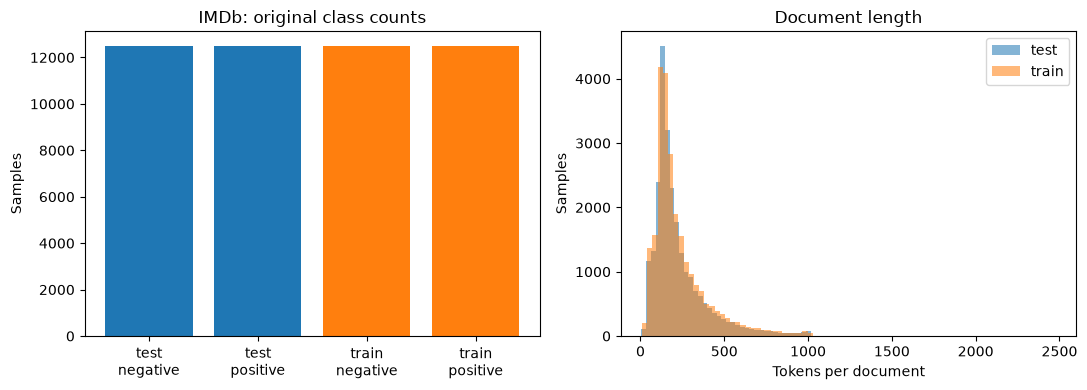

Dataset imbalance interpretation: complete independently in reflection_scan.pdf.


In [2]:
# 11. Inspect the original labeled dataset BEFORE any training.
raw = load_imdb(DATA)
raw_summary, raw_distribution, raw_lengths = inspect_dataset(raw)
print("11. Raw data audit")
display(raw_summary)
display(raw_distribution)
display(raw_lengths.groupby("official_split")[["characters", "tokens"]].describe())
raw_summary.to_csv(TABLES / "dataset_audit_raw.csv", index=False)
raw_distribution.to_csv(TABLES / "class_distribution_raw.csv", index=False)
raw_lengths.to_csv(TABLES / "document_lengths_raw.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split, group in raw_distribution.groupby("official_split"):
    axes[0].bar([f"{split}\n{c}" for c in group["class"]], group["count"])
axes[0].set(ylabel="Samples", title="IMDb: original class counts")
for split, group in raw_lengths.groupby("official_split"):
    axes[1].hist(group.tokens, bins=80, alpha=.55, label=split)
axes[1].set(xlabel="Tokens per document", ylabel="Samples", title="Document length")
axes[1].legend()
fig.tight_layout()
fig.savefig(TABLES / "dataset_inspection.png", dpi=160)
plt.show()
print("Dataset imbalance interpretation: complete independently in reflection_scan.pdf.")

In [3]:
# 12. data leakage
clean, cleaning_audit = clean_official_splits(raw)
official_train = clean.loc[clean.official_split.eq("train")].copy()
test = clean.loc[clean.official_split.eq("test")].copy().reset_index(drop=True)
train, validation = train_test_split(official_train, test_size=.2, random_state=SEED,
                                     stratify=official_train.label)
train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)
splits = {"train": train, "validation": validation, "test": test}
key_sets = {name: set(frame.document_key) for name, frame in splits.items()}
overlaps = []
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    count = len(key_sets[a] & key_sets[b])
    overlaps.append({"split_a": a, "split_b": b, "shared_token_document_keys": count})
    assert count == 0
split_distribution = pd.concat([
    frame.label.value_counts().sort_index().rename("count").reset_index().assign(split=name)
    for name, frame in splits.items()], ignore_index=True)
split_distribution["class"] = split_distribution.label.map(dict(zip(LABELS, LABEL_NAMES)))
split_distribution["percentage"] = split_distribution["count"] / split_distribution.groupby("split")["count"].transform("sum") * 100
print("12. Cleaning and split audit")
display(cleaning_audit)
display(split_distribution)
display(pd.DataFrame(overlaps))
cleaning_audit.to_csv(TABLES / "cleaning_audit.csv", index=False)
split_distribution.to_csv(TABLES / "split_distribution.csv", index=False)
pd.DataFrame(overlaps).to_csv(TABLES / "split_overlap_audit.csv", index=False)
manifest = pd.concat([frame[["sample_id", "document_key", "label"]].assign(split=name)
                      for name, frame in splits.items()], ignore_index=True)
manifest.to_csv(TABLES / "split_manifest.csv", index=False)
y_train = train.label.to_numpy()
y_validation = validation.label.to_numpy()
y_test = test.label.to_numpy()
print("Learned vocabulary, IDF, Word2Vec and scalers below are fitted on TRAIN only.")

12. Cleaning and split audit


,official_split,original,invalid_or_empty_removed,conflicting_label_groups,conflicting_label_rows_removed,duplicate_extra_rows_removed,cross_split_rows_removed,retained
0,train,25000,0,0,0,99,0,24901
1,test,25000,0,0,0,202,123,24675


,label,count,split,class,percentage
0,0,9944,train,negative,49.919679
1,1,9976,train,positive,50.080321
2,0,2487,validation,negative,49.929733
3,1,2494,validation,positive,50.070267
4,0,12264,test,negative,49.702128
5,1,12411,test,positive,50.297872


,split_a,split_b,shared_token_document_keys
0,train,validation,0
1,train,test,0
2,validation,test,0


Learned vocabulary, IDF, Word2Vec and scalers below are fitted on TRAIN only.


In [4]:
# 13. Core implementation: train-only representation, classifier and evaluation helpers.
STOPWORDS = sorted(set(ENGLISH_STOP_WORDS) - {"no", "not", "nor", "never"})
tfidf_cache = {}
models = {}
tuning_records = []

def fit_tfidf(ngram=(1, 1), max_features=20000, remove_stopwords=False):
    key = (ngram, max_features, remove_stopwords)
    if key not in tfidf_cache:
        start = time.perf_counter()
        vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None,
                                     lowercase=False, ngram_range=ngram,
                                     max_features=max_features, min_df=2,
                                     sublinear_tf=True, dtype=np.float32,
                                     stop_words=STOPWORDS if remove_stopwords else None)
        x_train = vectorizer.fit_transform(train.text)
        representation_seconds = time.perf_counter() - start
        x_validation = vectorizer.transform(validation.text)
        assert vectorizer.get_feature_names_out().size == x_train.shape[1]
        tfidf_cache[key] = (vectorizer, x_train, x_validation, representation_seconds)
    return tfidf_cache[key]

def tune_classifier(name, representation, x_train, x_validation, representation_seconds,
                    vocabulary_size, vectorizer=None, scaler=None, embedding=None, svm=False,
                    ngram=(1, 1), max_features=None, remove_stopwords=False):
    candidates = []
    start_all = time.perf_counter()
    for c in [0.1, 1.0, 10.0]:
        clf = (LinearSVC(C=c, random_state=SEED, max_iter=5000) if svm else
               LogisticRegression(C=c, solver="liblinear", random_state=SEED, max_iter=2000))
        start = time.perf_counter()
        clf.fit(x_train, y_train)
        seconds = time.perf_counter() - start
        assert np.max(clf.n_iter_) < clf.max_iter, f"Convergence check: {name}, C={c}"
        pred = clf.predict(x_validation)
        score = f1_score(y_validation, pred, pos_label=1, zero_division=0)
        tuning_records.append({"model": name, "C": c, "validation_accuracy": accuracy_score(y_validation, pred),
                               "validation_f1_positive": score, "classifier_fit_seconds": seconds})
        candidates.append((score, -c, clf, seconds))
    best = max(candidates, key=lambda item: (item[0], item[1]))
    models[name] = {"name": name, "representation": representation, "clf": best[2],
                    "C": best[2].C, "validation_f1_positive": best[0],
                    "vocabulary_size": vocabulary_size, "feature_dimension": x_train.shape[1],
                    "representation_fit_seconds": representation_seconds,
                    "classifier_fit_seconds": best[3],
                    "training_seconds": representation_seconds + best[3],
                    "search_seconds": time.perf_counter() - start_all,
                    "vectorizer": vectorizer, "scaler": scaler, "embedding": embedding,
                    "ngram": ngram, "max_features": max_features,
                    "remove_stopwords": remove_stopwords, "validation_features": x_validation}
    print(name, "C:", best[2].C, "validation F1:", round(best[0], 6))
    return models[name]


def transform_texts(model, texts):
    if model["vectorizer"] is not None:
        return model["vectorizer"].transform(texts)
    vectors, _ = average_embeddings([tokenize(text) for text in texts], model["embedding"])
    return model["scaler"].transform(vectors)


def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary",
                                                pos_label=1, zero_division=0)
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=LABELS).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f,
            "precision_macro": pm, "recall_macro": rm, "f1_macro": fm, "f1_weighted": fw,
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def validation_model_table(names):
    rows = []
    for name in names:
        model = models[name]
        predictions = model["clf"].predict(model["validation_features"])
        rows.append({"model": name, "representation": model["representation"],
                     "classifier": type(model["clf"]).__name__, "evaluation_split": "validation",
                     "C": model["C"], "vocabulary_size": model["vocabulary_size"],
                     "feature_dimension": model["feature_dimension"],
                     "training_time_seconds": model["training_seconds"],
                     **metrics(y_validation, predictions)})
    return pd.DataFrame(rows)

print("13. Core pipeline helpers defined; no model training occurs in this cell.")

13. Core pipeline helpers defined; no model training occurs in this cell.


In [5]:
# 14. Experiment 2: fit and report the TF-IDF + Logistic Regression baseline.
vectorizer, x_train_tfidf, x_validation_tfidf, tfidf_seconds = fit_tfidf()
baseline = tune_classifier("tfidf_unigram_lr", "TF-IDF unigram", x_train_tfidf,
                           x_validation_tfidf, tfidf_seconds, len(vectorizer.vocabulary_),
                           vectorizer=vectorizer, max_features=20000)
display(pd.DataFrame(tuning_records))
print("Training time = representation fit + selected classifier fit; search time is reported separately.")
baseline_validation = validation_model_table(["tfidf_unigram_lr"])
print("14. Baseline metrics on validation; final held-out test evaluation is in section 19.")
display(baseline_validation)
baseline_validation.to_csv(TABLES / "baseline_validation.csv", index=False)

tfidf_unigram_lr C: 1.0 validation F1: 0.894945


,model,C,validation_accuracy,validation_f1_positive,classifier_fit_seconds
0,tfidf_unigram_lr,0.1,0.861273,0.865276,0.471360
1,tfidf_unigram_lr,1.0,0.893194,0.894945,0.803804
2,tfidf_unigram_lr,10.0,0.893395,0.894747,1.569551


Training time = representation fit + selected classifier fit; search time is reported separately.
14. Baseline metrics on validation; final held-out test evaluation is in section 19.


,model,representation,classifier,evaluation_split,C,vocabulary_size,feature_dimension,training_time_seconds,accuracy,precision,recall,f1,precision_macro,recall_macro,f1_macro,f1_weighted,tn,fp,fn,tp
0,tfidf_unigram_lr,TF-IDF unigram,LogisticRegression,validation,1.0,20000,20000,8.548688,0.893194,0.881712,0.908581,0.894945,0.893573,0.893172,0.893164,0.893167,2183,304,228,2266


In [6]:
# 15. Train Average Word2Vec on TRAIN only; same Logistic Regression C grid.
start = time.perf_counter()
w2v = Word2Vec(sentences=train.tokens.tolist(), vector_size=100, window=5,
               min_count=2, sg=1, negative=5, epochs=10, workers=1, seed=SEED)
x_train_w2v, train_coverage = average_embeddings(train.tokens.tolist(), w2v.wv)
scaler = StandardScaler().fit(x_train_w2v)
x_train_w2v = scaler.transform(x_train_w2v)
w2v_seconds = time.perf_counter() - start
x_validation_w2v, validation_coverage = average_embeddings(validation.tokens.tolist(), w2v.wv)
x_validation_w2v = scaler.transform(x_validation_w2v)
w2v_model = tune_classifier("average_word2vec_lr", "Average Word2Vec", x_train_w2v,
                            x_validation_w2v, w2v_seconds, len(w2v.wv),
                            scaler=scaler, embedding=w2v.wv)
print("Word2Vec config:", {"training_split": "train only", "documents": len(train),
      "vector_size": 100, "window": 5, "min_count": 2, "sg": 1,
      "negative": 5, "epochs": 10, "workers": 1, "seed": SEED, "vocabulary": len(w2v.wv)})
coverage_summary = pd.DataFrame([
    {"split": name, "mean_token_coverage": cov.coverage.mean(),
     "total_token_coverage": cov.known_tokens.sum() / cov.total_tokens.sum(),
     "zero_vector_documents": int(cov.known_tokens.eq(0).sum())}
    for name, cov in [("train", train_coverage), ("validation", validation_coverage)]])
display(coverage_summary)
coverage_summary.to_csv(TABLES / "word2vec_coverage_train_validation.csv", index=False)
# Optional model C from section 15.
tune_classifier("tfidf_unigram_svm", "TF-IDF unigram", x_train_tfidf,
                x_validation_tfidf, tfidf_seconds, len(vectorizer.vocabulary_),
                vectorizer=vectorizer, svm=True, max_features=20000)
representation_names = ["tfidf_unigram_lr", "average_word2vec_lr", "tfidf_unigram_svm"]
representation_validation = validation_model_table(representation_names)
print("15. Representation comparison on validation; final test metrics are in section 19.")
display(representation_validation)
representation_validation.to_csv(TABLES / "representation_validation.csv", index=False)

average_word2vec_lr C: 1.0 validation F1: 0.865922
Word2Vec config: {'training_split': 'train only', 'documents': 19920, 'vector_size': 100, 'window': 5, 'min_count': 2, 'sg': 1, 'negative': 5, 'epochs': 10, 'workers': 1, 'seed': 42, 'vocabulary': 45034}


,split,mean_token_coverage,total_token_coverage,zero_vector_documents
0,train,0.994098,0.994023,0
1,validation,0.989414,0.988238,0


tfidf_unigram_svm C: 0.1 validation F1: 0.893449
15. Representation comparison on validation; final test metrics are in section 19.


,model,representation,classifier,evaluation_split,C,vocabulary_size,feature_dimension,training_time_seconds,accuracy,precision,recall,f1,precision_macro,recall_macro,f1_macro,f1_weighted,tn,fp,fn,tp
0,tfidf_unigram_lr,TF-IDF unigram,LogisticRegression,validation,1.0,20000,20000,8.548688,0.893194,0.881712,0.908581,0.894945,0.893573,0.893172,0.893164,0.893167,2183,304,228,2266
1,average_word2vec_lr,Average Word2Vec,LogisticRegression,validation,1.0,45034,100,473.918970,0.865087,0.861795,0.870088,0.865922,0.865124,0.865080,0.865082,0.865083,2139,348,324,2170
2,tfidf_unigram_svm,TF-IDF unigram,LinearSVC,validation,0.1,20000,20000,8.439294,0.891588,0.879565,0.907779,0.893449,0.892005,0.891565,0.891555,0.891558,2177,310,230,2264


In [7]:
# 17. Experiment 4: word-order and negation probes.
probe_texts = ["this movie is good", "this movie is not good",
               "good is this movie", "not this movie is good", "this movie is very good"]
raw_probe_vectors, probe_coverage = average_embeddings([tokenize(s) for s in probe_texts], w2v.wv)
probe_records = []
for name in ["tfidf_unigram_lr", "average_word2vec_lr"]:
    model = models[name]
    features = transform_texts(model, probe_texts)
    probs = model["clf"].predict_proba(features)[:, 1]
    pred = model["clf"].predict(features)
    for text, label, prob in zip(probe_texts, pred, probs):
        probe_records.append({"model": name, "text": text, "predicted": LABEL_NAMES[label],
                              "probability_positive": prob})
print("17. Probes (synthetic examples; not an evaluation dataset)")
display(pd.DataFrame(probe_records))
pair_records = []
for a, b in [(0, 1), (0, 2), (1, 3)]:
    va, vb = raw_probe_vectors[a], raw_probe_vectors[b]
    denom = np.linalg.norm(va) * np.linalg.norm(vb)
    pair_records.append({"sentence_a": probe_texts[a], "sentence_b": probe_texts[b],
                         "raw_average_cosine": float(np.dot(va, vb) / denom) if denom else np.nan,
                         "max_abs_vector_difference": float(np.max(np.abs(va - vb)))})
display(pd.DataFrame(pair_records))
display(probe_coverage.assign(text=probe_texts))
pd.DataFrame(probe_records).to_csv(TABLES / "negation_word_order_predictions.csv", index=False)
pd.DataFrame(pair_records).to_csv(TABLES / "word_order_vector_comparison.csv", index=False)

17. Probes (synthetic examples; not an evaluation dataset)


,model,text,predicted,probability_positive
0,tfidf_unigram_lr,this movie is good,positive,0.706186
1,tfidf_unigram_lr,this movie is not good,negative,0.410895
2,tfidf_unigram_lr,good is this movie,positive,0.706186
3,tfidf_unigram_lr,not this movie is good,negative,0.410895
4,tfidf_unigram_lr,this movie is very good,positive,0.919611
5,average_word2vec_lr,this movie is good,positive,0.976614
6,average_word2vec_lr,this movie is not good,positive,0.807005
7,average_word2vec_lr,good is this movie,positive,0.976614
8,average_word2vec_lr,not this movie is good,positive,0.807005
9,average_word2vec_lr,this movie is very good,positive,0.999917


,sentence_a,sentence_b,raw_average_cosine,max_abs_vector_difference
0,this movie is good,this movie is not good,0.977653,1.069354e-01
1,this movie is good,good is this movie,1.000000,2.980232e-08
2,this movie is not good,not this movie is good,1.000000,5.960464e-08


,total_tokens,known_tokens,oov_tokens,coverage,text
0,4,4,0,1.0,this movie is good
1,5,5,0,1.0,this movie is not good
2,4,4,0,1.0,good is this movie
3,5,5,0,1.0,not this movie is good
4,5,5,0,1.0,this movie is very good


In [8]:
# 18. Unigram vs unigram+bigram: same split and validation selection protocol.
bigram_vectorizer, x_train_bigram, x_validation_bigram, bigram_seconds = fit_tfidf((1, 2), 40000)
tune_classifier("tfidf_unigram_bigram_lr", "TF-IDF unigram+bigram", x_train_bigram,
                x_validation_bigram, bigram_seconds, len(bigram_vectorizer.vocabulary_),
                vectorizer=bigram_vectorizer, ngram=(1, 2), max_features=40000)
print("Vocabulary caps: unigram 20,000; unigram+bigram 40,000.")
display(pd.DataFrame([
    {"model": name, "feature": feature, "present": feature in model["vectorizer"].vocabulary_}
    for name, model in models.items() if model["vectorizer"] is not None
    for feature in ["not", "good", "not good", "very good"]]))
ngram_validation = validation_model_table(["tfidf_unigram_lr", "tfidf_unigram_bigram_lr"])
print("18. N-gram comparison on validation; final test metrics are in section 19.")
display(ngram_validation[["model", "evaluation_split", "vocabulary_size", "f1", "training_time_seconds"]])
ngram_validation.to_csv(TABLES / "ngram_validation.csv", index=False)

tfidf_unigram_bigram_lr C: 10.0 validation F1: 0.900812
Vocabulary caps: unigram 20,000; unigram+bigram 40,000.


,model,feature,present
0,tfidf_unigram_lr,not,True
1,tfidf_unigram_lr,good,True
2,tfidf_unigram_lr,not good,False
3,tfidf_unigram_lr,very good,False
4,tfidf_unigram_svm,not,True
5,tfidf_unigram_svm,good,True
6,tfidf_unigram_svm,not good,False
7,tfidf_unigram_svm,very good,False
8,tfidf_unigram_bigram_lr,not,True
9,tfidf_unigram_bigram_lr,good,True


18. N-gram comparison on validation; final test metrics are in section 19.


,model,evaluation_split,vocabulary_size,f1,training_time_seconds
0,tfidf_unigram_lr,validation,20000,0.894945,8.548688
1,tfidf_unigram_bigram_lr,validation,40000,0.900812,25.792388


In [9]:
# 19. Evaluation: frozen configurations and complete held-out TEST metrics.
tuning = pd.DataFrame(tuning_records)
tuning.to_csv(TABLES / "validation_hyperparameters.csv", index=False)
display(tuning)
locked_configs = pd.DataFrame([
    {key: model[key] for key in ["name", "representation", "C", "validation_f1_positive",
                               "vocabulary_size", "feature_dimension", "training_seconds",
                               "search_seconds", "ngram", "max_features", "remove_stopwords"]}
    for model in models.values()])
locked_configs.to_csv(TABLES / "locked_model_configs.csv", index=False)

result_records = []
test_outputs = {}
per_class = []
for name, model in models.items():
    start = time.perf_counter()
    features = transform_texts(model, test.text.tolist())
    pred = model["clf"].predict(features)
    decision = model["clf"].decision_function(features)
    probability = (model["clf"].predict_proba(features)[:, 1]
                   if hasattr(model["clf"], "predict_proba") else np.full(len(test), np.nan))
    infer_seconds = time.perf_counter() - start
    test_outputs[name] = {"pred": pred, "decision": decision, "probability": probability}
    record = {"model": name, "representation": model["representation"],
              "classifier": type(model["clf"]).__name__, "evaluation_split": "test",
              "positive_label": 1, "positive_class": "positive", "C": model["C"],
              "threshold": .5 if hasattr(model["clf"], "predict_proba") else np.nan,
              "vocabulary_size": model["vocabulary_size"], "feature_dimension": model["feature_dimension"],
              "train_samples": len(train), "validation_samples": len(validation), "test_samples": len(test),
              "training_time_seconds": model["training_seconds"],
              "representation_fit_seconds": model["representation_fit_seconds"],
              "classifier_fit_seconds": model["classifier_fit_seconds"],
              "classifier_search_seconds": model["search_seconds"], "inference_seconds": infer_seconds,
              "validation_f1": model["validation_f1_positive"], **metrics(y_test, pred)}
    result_records.append(record)
    p, r, f, support = precision_recall_fscore_support(y_test, pred, labels=LABELS, zero_division=0)
    for label, pp, rr, ff, ss in zip(LABELS, p, r, f, support):
        per_class.append({"model": name, "class": LABEL_NAMES[label], "precision": pp,
                          "recall": rr, "f1": ff, "support": int(ss)})
results = pd.DataFrame(result_records)
results.to_csv(BASE / "results.csv", index=False)
pd.DataFrame(per_class).to_csv(TABLES / "per_class_metrics.csv", index=False)
core_names = ["tfidf_unigram_lr", "average_word2vec_lr", "tfidf_unigram_svm", "tfidf_unigram_bigram_lr"]
print("19. TEST metrics: precision/recall/F1 use positive=1; macro and weighted F1 are separate columns.")
display(results.loc[results.model.isin(core_names), ["model", "accuracy", "precision", "recall", "f1",
        "f1_macro", "training_time_seconds", "vocabulary_size", "feature_dimension"]])

print("19. Per-class TEST metrics")
display(pd.DataFrame(per_class))
test_vectors, test_coverage = average_embeddings(test.tokens.tolist(), w2v.wv)
coverage_summary_test = pd.DataFrame([{"split": "test", "mean_token_coverage": test_coverage.coverage.mean(),
    "total_token_coverage": test_coverage.known_tokens.sum() / test_coverage.total_tokens.sum(),
    "zero_vector_documents": int(test_coverage.known_tokens.eq(0).sum())}])
display(coverage_summary_test)
coverage_summary_test.to_csv(TABLES / "word2vec_coverage_test.csv", index=False)

,model,C,validation_accuracy,validation_f1_positive,classifier_fit_seconds
0,tfidf_unigram_lr,0.1,0.861273,0.865276,0.471360
1,tfidf_unigram_lr,1.0,0.893194,0.894945,0.803804
2,tfidf_unigram_lr,10.0,0.893395,0.894747,1.569551
3,average_word2vec_lr,0.1,0.864887,0.865695,0.823835
4,average_word2vec_lr,1.0,0.865087,0.865922,0.738679
5,average_word2vec_lr,10.0,0.865087,0.865922,0.733697
6,tfidf_unigram_svm,0.1,0.891588,0.893449,0.694411
7,tfidf_unigram_svm,1.0,0.890986,0.892283,0.615516
8,tfidf_unigram_svm,10.0,0.872917,0.873526,1.466840
9,tfidf_unigram_bigram_lr,0.1,0.862477,0.866028,0.694361


19. TEST metrics: precision/recall/F1 use positive=1; macro and weighted F1 are separate columns.


,model,accuracy,precision,recall,f1,f1_macro,training_time_seconds,vocabulary_size,feature_dimension
0,tfidf_unigram_lr,0.889970,0.887716,0.894368,0.891030,0.889959,8.548688,20000,20000
1,average_word2vec_lr,0.859939,0.866738,0.852631,0.859626,0.859939,473.918970,45034,100
2,tfidf_unigram_svm,0.891550,0.888623,0.896785,0.892685,0.891538,8.439294,20000,20000
3,tfidf_unigram_bigram_lr,0.903343,0.902910,0.905165,0.904036,0.903338,25.792388,40000,40000


19. Per-class TEST metrics


,model,class,precision,recall,f1,support
0,tfidf_unigram_lr,negative,0.892285,0.885519,0.888889,12264
1,tfidf_unigram_lr,positive,0.887716,0.894368,0.891030,12411
2,average_word2vec_lr,negative,0.853281,0.867335,0.860251,12264
3,average_word2vec_lr,positive,0.866738,0.852631,0.859626,12411
4,tfidf_unigram_svm,negative,0.894568,0.886252,0.890391,12264
5,tfidf_unigram_svm,positive,0.888623,0.896785,0.892685,12411
6,tfidf_unigram_bigram_lr,negative,0.903785,0.901500,0.902641,12264
7,tfidf_unigram_bigram_lr,positive,0.902910,0.905165,0.904036,12411


,split,mean_token_coverage,total_token_coverage,zero_vector_documents
0,test,0.985786,0.984484,0


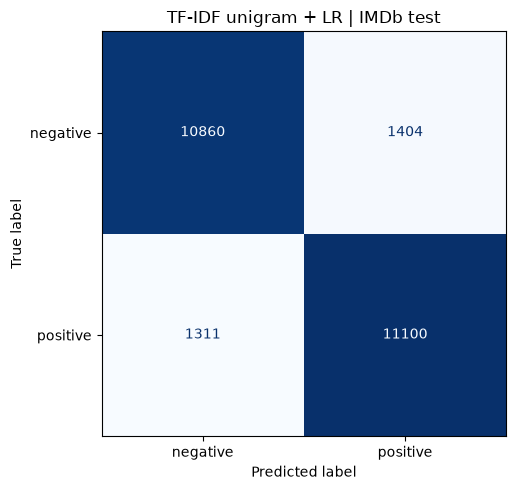

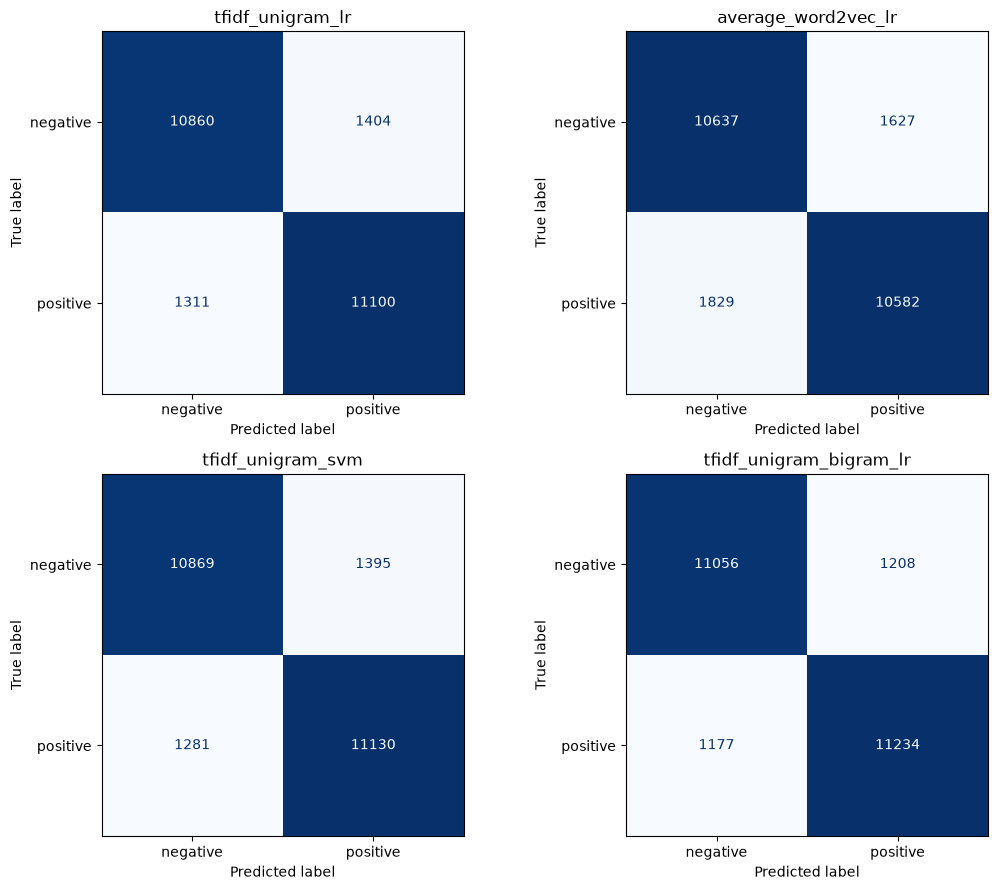

,model,tn,fp,fn,tp
0,tfidf_unigram_lr,10860,1404,1311,11100
1,average_word2vec_lr,10637,1627,1829,10582
2,tfidf_unigram_svm,10869,1395,1281,11130
3,tfidf_unigram_bigram_lr,11056,1208,1177,11234


In [10]:
# 20. Confusion matrices: rows = actual, columns = predicted; negative then positive.
fig, ax = plt.subplots(figsize=(6, 5))
baseline_cm = confusion_matrix(y_test, test_outputs["tfidf_unigram_lr"]["pred"], labels=LABELS)
ConfusionMatrixDisplay(baseline_cm, display_labels=LABEL_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("TF-IDF unigram + LR | IMDb test")
fig.tight_layout()
fig.savefig(BASE / "confusion_matrix.png", dpi=180)
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for name, ax in zip(core_names, axes.ravel()):
    cm = confusion_matrix(y_test, test_outputs[name]["pred"], labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.tight_layout()
fig.savefig(TABLES / "confusion_matrices_comparison.png", dpi=160)
plt.show()
display(results[["model", "tn", "fp", "fn", "tp"]])

In [11]:
# 21. Candidate examples and full predictions; the student selects and explains causes.
candidate_frames = []
for name in core_names:
    out = test_outputs[name]
    predictions = test[["sample_id", "text", "label"]].copy()
    predictions["true_class"] = predictions.label.map(dict(zip(LABELS, LABEL_NAMES)))
    predictions["predicted_label"] = out["pred"]
    predictions["predicted_class"] = [LABEL_NAMES[i] for i in out["pred"]]
    predictions["probability_positive"] = out["probability"]
    predictions["decision_score"] = out["decision"]
    predictions["correct"] = predictions.label.eq(predictions.predicted_label)
    predictions["model"] = name
    predictions.to_csv(TABLES / f"predictions_{name}.csv", index=False)
    for correct in [True, False]:
        for label in LABELS:
            pool = predictions.loc[predictions.correct.eq(correct) & predictions.label.eq(label)]
            chosen = pool.sample(n=min(6, len(pool)), random_state=SEED).copy()
            candidate_frames.append(chosen)
candidates = pd.concat(candidate_frames, ignore_index=True)
candidates.to_csv(TABLES / "error_analysis_candidates.csv", index=False)
print("21. Candidate pool: up to 12 correct + 12 incorrect per model, stratified by true class.")
print("Full text is preserved in CSV. Cause/category/analysis is left for the student's handwritten work.")
display(candidates[["model", "sample_id", "true_class", "predicted_class", "correct", "text"]])
# A compact 3 correct + 3 incorrect evidence sample for the baseline, no cause labels.
compact = pd.concat([candidates.loc[candidates.model.eq("tfidf_unigram_lr") & candidates.correct.eq(flag)].head(3)
                     for flag in [True, False]], ignore_index=True)
display(compact[["sample_id", "text", "true_class", "predicted_class", "probability_positive"]])
compact.to_csv(TABLES / "six_baseline_examples.csv", index=False)

21. Candidate pool: up to 12 correct + 12 incorrect per model, stratified by true class.
Full text is preserved in CSV. Cause/category/analysis is left for the student's handwritten work.


,model,sample_id,true_class,predicted_class,correct,text
0,tfidf_unigram_lr,test:39,negative,negative,True,"Wow, what an overrated movie this turned out to be! It was supposed to be ""an extremely suspenseful tale of a crazed..."
1,tfidf_unigram_lr,test:8329,negative,negative,True,"The sound is terrible, the picture is worse than worse, the acting is awful, the female leading actress is chubby, a..."
2,tfidf_unigram_lr,test:10025,negative,negative,True,"JP3 lacks the Spielberg touch. It's an all-out assault on the senses featuring ""in your face"" dinosaurs. Watching th..."
3,tfidf_unigram_lr,test:6872,negative,negative,True,This is a pretty run of the mill family move that I am sure most children will enjoy but with really no that much to...
4,tfidf_unigram_lr,test:8133,negative,negative,True,"According to Milan Kundera, a porcelain-cat holding a red rose is denying the crap. Well, those criminals guilty of ..."
...,...,...,...,...,...,...
91,tfidf_unigram_bigram_lr,test:20844,positive,negative,False,"I know it was supposed to be a long walk, but really!!!!<br /><br />The costumes were a bit yuk, but still... it was..."
92,tfidf_unigram_bigram_lr,test:13360,positive,negative,False,The movie was very good. I'm an avid mystery fan and I usually figure out who is going to be killed and who did the ...
93,tfidf_unigram_bigram_lr,test:20975,positive,negative,False,I watched this film early 70's.It is the best film I have ever watched And I will never forget it as long as I live....
94,tfidf_unigram_bigram_lr,test:19623,positive,negative,False,One True Thing proves that it's the characters which make a movie. Streep will surely receive an Oscar nomination fo...


,sample_id,text,true_class,predicted_class,probability_positive
0,test:39,"Wow, what an overrated movie this turned out to be! It was supposed to be ""an extremely suspenseful tale of a crazed...",negative,negative,0.379803
1,test:8329,"The sound is terrible, the picture is worse than worse, the acting is awful, the female leading actress is chubby, a...",negative,negative,0.021161
2,test:10025,"JP3 lacks the Spielberg touch. It's an all-out assault on the senses featuring ""in your face"" dinosaurs. Watching th...",negative,negative,0.283820
3,test:9280,"This movie is a window on the world of Britain in 1973 - a world of holiday camps, fags and birds. I was actually at...",negative,positive,0.605164
4,test:4448,"When I was young, I was a big fan of Chuck Norris. I just begun getting out all his old movies on video so I can see...",negative,positive,0.894803
5,test:5854,"If you thought Herbie trying to kill himself by driving off a bridge in 'The Love Bug' was daft, wait 'till you see ...",negative,positive,0.541882


In [12]:
# 22. Inspect LR coefficients and numeric term contributions, without interpretation.
weight_frames = []
contribution_records = []
for name in ["tfidf_unigram_lr", "tfidf_unigram_bigram_lr"]:
    model = models[name]
    terms = model["vectorizer"].get_feature_names_out()
    weights = model["clf"].coef_[0]
    assert model["clf"].classes_.tolist() == [0, 1]
    table = pd.DataFrame({"model": name, "feature": terms, "weight": weights})
    table["coefficient_class"] = "positive=1 relative to negative=0"
    top = pd.concat([table.nlargest(20, "weight").assign(side="top_positive"),
                     table.nsmallest(20, "weight").assign(side="top_negative")])
    weight_frames.append(top)
    print("22.", name, "bias:", float(model["clf"].intercept_[0]))
    display(top[["side", "feature", "weight"]])
    selected = candidates.loc[candidates.model.eq(name)]
    for row in selected.itertuples():
        features = model["vectorizer"].transform([row.text]).tocsr()
        values = features.data * weights[features.indices]
        reconstructed = values.sum() + model["clf"].intercept_[0]
        assert np.isclose(reconstructed, row.decision_score, atol=1e-5)
        ranked = np.argsort(np.abs(values))[::-1][:10]
        for rank, idx in enumerate(ranked, 1):
            contribution_records.append({"model": name, "sample_id": row.sample_id, "rank": rank,
                                         "feature": terms[features.indices[idx]],
                                         "tfidf_value": features.data[idx],
                                         "coefficient": weights[features.indices[idx]],
                                         "contribution_to_logit": values[idx]})
pd.concat(weight_frames).to_csv(TABLES / "top_model_weights.csv", index=False)
pd.DataFrame(contribution_records).to_csv(TABLES / "candidate_feature_contributions.csv", index=False)

22. tfidf_unigram_lr bias: -0.09272524069148709


,side,feature,weight
7834,top_positive,great,6.993990
6309,top_positive,excellent,5.529416
1835,top_positive,best,4.977745
13092,top_positive,perfect,4.548516
190,top_positive,7,4.256737
19732,top_positive,wonderful,4.078054
7295,top_positive,fun,3.782082
10664,top_positive,love,3.770917
10667,top_positive,loved,3.685899
751,top_positive,amazing,3.652622


22. tfidf_unigram_bigram_lr bias: 0.21784720835315619


,side,feature,weight
14265,top_positive,great,10.194433
11528,top_positive,excellent,9.006383
25415,top_positive,perfect,8.321771
308,top_positive,7,8.292204
39198,top_positive,wonderful,7.395032
13381,top_positive,fun,6.818076
32417,top_positive,the best,6.772614
11013,top_positive,enjoyable,6.299521
5649,top_positive,best,6.217382
2547,top_positive,amazing,6.074219


In [13]:
# 23. Application A: sentiment classification with the validation-selected model.
APPLICATION_MODEL = max(models, key=lambda name: (models[name]["validation_f1_positive"], name))
application_texts = ["I love this movie. The acting is excellent and the story is engaging.",
                     "This movie is terrible. I regret spending time on it.",
                     "The film looks beautiful, but the story is not good.",
                     "I expected a bad movie, but I enjoyed it."]
application = models[APPLICATION_MODEL]
x_application = transform_texts(application, application_texts)
application_labels = application["clf"].predict(x_application)
application_scores = application["clf"].decision_function(x_application)
application_probabilities = (application["clf"].predict_proba(x_application)[:, 1]
                             if hasattr(application["clf"], "predict_proba") else np.full(len(application_texts), np.nan))
application_results = pd.DataFrame({"text": application_texts, "model": APPLICATION_MODEL,
                                    "predicted_class": [LABEL_NAMES[x] for x in application_labels],
                                    "decision_score": application_scores,
                                    "probability_positive": application_probabilities})
display(application_results)
application_results.to_csv(TABLES / "application_predictions.csv", index=False)

(TABLES / "application_selection.json").write_text(json.dumps(
    {"model": APPLICATION_MODEL, "selection_split": "validation", "selection_metric": "F1 positive",
     "threshold": 0.5}, indent=2), encoding="utf-8")

,text,model,predicted_class,decision_score,probability_positive
0,I love this movie. The acting is excellent and the story is engaging.,tfidf_unigram_bigram_lr,positive,3.812091,0.978376
1,This movie is terrible. I regret spending time on it.,tfidf_unigram_bigram_lr,negative,-3.626809,0.025912
2,"The film looks beautiful, but the story is not good.",tfidf_unigram_bigram_lr,negative,-0.237313,0.440949
3,"I expected a bad movie, but I enjoyed it.",tfidf_unigram_bigram_lr,negative,-0.154038,0.461566


132

In [14]:
# 26. Deliverables: validate generated files and save reproducibility metadata.
for item in result_records:
    assert item["tn"] + item["fp"] + item["fn"] + item["tp"] == len(test)
    assert all(0 <= item[metric] <= 1 for metric in ["accuracy", "precision", "recall", "f1"])
assert {"tfidf_unigram_lr", "average_word2vec_lr", "tfidf_unigram_bigram_lr"} <= set(results.model)
required = ["README.md", "calculations.md", "prediction.md", "classification.ipynb",
            "preprocessing.py", "results.csv", "confusion_matrix.png", "error_analysis.md", "reflection.md"]
assert all((BASE / file).exists() for file in required)
metadata = {"dataset": DATASET_URL, "revision": DATASET_REVISION, "seed": SEED,
            "dataset_file_sha256": {split: sha256_file(DATA / pair[0]) for split, pair in FILES.items()},
            "split_sizes": {name: len(frame) for name, frame in splits.items()},
            "prediction_completion": "User confirmed before model execution",
            "test_used_for_selection": False, "application_model": APPLICATION_MODEL,
            "primary_precision_recall_f1_average": "binary, positive label 1",
            "w2v_fitting_data": "training split only", "versions": versions, "notebook_section_order": [10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23, 26]}
(TABLES / "run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Code deliverables created; independent handwritten PDF scans still need to be added.")
display(pd.DataFrame({"required_file": required, "exists": [(BASE / f).exists() for f in required]}))

Code deliverables created; independent handwritten PDF scans still need to be added.


,required_file,exists
0,README.md,True
1,calculations.md,True
2,prediction.md,True
3,classification.ipynb,True
4,preprocessing.py,True
5,results.csv,True
6,confusion_matrix.png,True
7,error_analysis.md,True
8,reflection.md,True
